# Cameron Peak and East Troublesome Fire Burn Severity
## Data Download

- **Objective:**
For this notebook, all of the data needed for burn severity analysis of the 2020 Cameron Peak and East Troublesome fires is downloaded and saved to the data folder. This includes the fire perimeters, the official Monitoring Trends in Burn Severity (MTBS) data, watershed boundaries, a Wildland Urban Interface (WUI) map, and summer satellite composites of burn and vegetation indices for every year from 2019 to 2026.

- **Objective goals:**
    - Download the final fire perimeters for both fires from National Interagency Fire Center (NIFC)
    - Define a study area box around each fire that all of the other data is clipped to
    - Download the MTBS fire records, dNBR thresholds, and the 2020 MTBS burn severity map
    - Download the USGS HUC12 subwatersheds around the fires
    - Load the WUI map clip saved in this repo
    - Build summer median NBR and NDVI composites from Harmonized Landsat and Sentinel-2 (HLS) data for 2019-2026

---

### Prerequisites & Setup

Mandatory libraries:
- geopandas - vector data (perimeters, watersheds)
- rioxarray / xarray - raster data (MTBS, WUI, HLS)
- requests - API queries to the ArcGIS REST services
- earthaccess - NASA Earthdata login and HLS search
- hvplot - interactive maps
- matplotlib - raster maps

Environment:
- Conda environment fire_severity with geospatial dependencies installed (conda env create -f environment.yml)
- NASA Earthdata account for the HLS data

Data sources:
- Fire perimeters: [National Interagency Fire Center (NIFC), InterAgency Fire Perimeter History](https://data-nifc.opendata.arcgis.com/) (ArcGIS REST Feature Service)
- Burn severity: [Monitoring Trends in Burn Severity (MTBS)](https://www.mtbs.gov/) burned area boundaries (USFS ArcGIS REST Map Service) and yearly burn severity mosaics (ArcGIS REST Image Service)
- Watersheds: [USGS Watershed Boundary Dataset](https://www.usgs.gov/national-hydrography/watershed-boundary-dataset), HUC12 subwatersheds (ArcGIS REST Map Service)
- Wildland Urban Interface: [WUI Mapping Tool](https://github.com/maxwarnock/WUI_Mapping_Tool) output for Colorado (2019). A clip around the fires is saved in this repo (data/wui/wui_CO_2019_clip.tif)
- Satellite imagery: [NASA Harmonized Landsat and Sentinel-2 (HLS) v2.0](https://hls.gsfc.nasa.gov/), Landsat 8/9 and Sentinel-2 (NASA Earthdata)

Notes:
- All rasters are saved in UTM zone 13N on a 30m grid that lines up with the HLS pixels, except for the WUI map, which keeps its original 250m grid
- The study area for each fire is the fire perimeter plus a 5km buffer

---

### Methodology

#### 1. Download Fire Perimeters
- Download the NIFC fire perimeter service for the two fires
- Save the perimeters as a GeoPackage

#### 2. Define the Study Areas
- Buffer each perimeter by 5km and snap the box to the 30m HLS grid

#### 3. Download MTBS Data
- Download the MTBS burned area boundaries for both fires (fire records and dNBR thresholds)
- Export the 2020 MTBS burn severity map for each study area

#### 4. Download Watersheds
- Download the HUC12 subwatersheds that overlap the study areas

#### 5. Load the WUI Map
- Open the WUI map clip saved in data/wui and check it against the study areas

#### 6. Build HLS Summer Composites
- Log in to NASA Earthdata and search for HLS scenes in the summer window of each year
- Mask clouds, cloud shadows, snow, and water using the HLS quality band (Fmask)
- Calculate NBR and NDVI for each scene
- Take the median of the clear scenes at each pixel to build one composite per year

# Libraries

In [1]:
### file paths, OS operations, utilities
import os
import pathlib
import json
import warnings

### data handling
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely.geometry import box

### rasters
import rioxarray as rxr
import xarray as xr

### web requests / data download
import requests

### NASA earthdata access 
import earthaccess

### visualization
import hvplot.pandas
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

### progress bar
from tqdm.notebook import tqdm

### hide the warning for pixels with no clear looks when taking the median
warnings.filterwarnings("ignore", message="All-NaN slice encountered")

### hide earthaccess warnings about changes in its next version
warnings.filterwarnings("ignore", category=FutureWarning, module="earthaccess")

# Primary Directory

In [2]:
### set up root file path
# Walk up from the current directory to find the repo root (contains .git)
_cwd = pathlib.Path(os.getcwd()).resolve()
repo_root = next(
    (p for p in [_cwd] + list(_cwd.parents) if (p / '.git').exists()),
    _cwd
)
os.chdir(repo_root)

data_dir = os.path.join(repo_root, 'data')
os.makedirs(data_dir, exist_ok=True)

print('Repo root:', repo_root)

Repo root: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity


# Secondary Directories

In [3]:
### set a directory for the fire perimeter data
perimeter_dir = os.path.join(data_dir, 'perimeters')
os.makedirs(perimeter_dir, exist_ok=True)

### set a directory for the MTBS data
mtbs_dir = os.path.join(data_dir, 'mtbs')
os.makedirs(mtbs_dir, exist_ok=True)

### set a directory for the watershed data
watershed_dir = os.path.join(data_dir, 'watersheds')
os.makedirs(watershed_dir, exist_ok=True)

### set a directory for the WUI data
wui_dir = os.path.join(data_dir, 'wui')
os.makedirs(wui_dir, exist_ok=True)

### set a directory for the HLS composites
hls_dir = os.path.join(data_dir, 'hls')
os.makedirs(hls_dir, exist_ok=True)

### Study Area Settings
These settings are used throughout the notebook. Both fires burned in 2020. All of the rasters except the WUI map are put in UTM zone 13N, which is the projection the HLS satellite tiles use over northern Colorado, so the HLS pixels never need to be resampled. The 5km buffer adds unburned land around each fire, which is useful for comparing burned and unburned areas later on.

In [4]:
### fire year
fire_year = 2020

### projected coordinate system for the study area: UTM zone 13N (meters)
utm_crs = "EPSG:32613"

### pixel size of the HLS data (meters)
cell_size = 30

### buffer around each fire perimeter (meters)
buffer_m = 5000

# 1. Fire Perimeters (NIFC)
The National Interagency Fire Center (NIFC) keeps the official final perimeters of wildfires in the US. The perimeters are shared through an ArcGIS REST Feature Service, and they can be downloaded directly with the requests library. NIFC splits its perimeter history into layers by decade, and the 2020s layer has both fires.

### Define the ArcGIS download function
Three of the data sources in this notebook (NIFC, MTBS, and the USGS watersheds) are ArcGIS REST services, so one function is used to download from all of them. ArcGIS services only send back a limited number of features per request (usually 1,000 or 2,000), so the function asks for one page of features at a time until everything has been downloaded.

In [5]:
### create a function to download an ArcGIS REST service layer
def download_arcgis(layer_url, where="1=1", bbox=None, out_fields="*", max_offset=None):
    """
    Download an ArcGIS REST layer and return the results as a GeoDataFrame

    Args:
    layer_url (str): url of the ArcGIS layer 
    where (str): SQL filter on the attributes, "1=1" returns everything
    bbox (tuple): optional box to search in (min lon, min lat, max lon, max lat)
    out_fields (str): fields to return, "*" returns all of them
    max_offset (float): optional polygon simplification in degrees, for very detailed polygons

    Returns:
    geopandas.GeoDataFrame: all of the features from the query, in EPSG:4326
    """

    ### set the query parameters
    params = {
        "where": where,
        "outFields": out_fields,
        "returnGeometry": "true",
        "outSR": 4326,
        "f": "geojson",
    }

    ### add the search box if there is one
    if bbox is not None:
        params["geometry"] = ",".join(str(value) for value in bbox)
        params["geometryType"] = "esriGeometryEnvelope"
        params["inSR"] = 4326
        params["spatialRel"] = "esriSpatialRelIntersects"

    ### simplify the polygons if asked
    if max_offset is not None:
        params["maxAllowableOffset"] = max_offset

    ### download one page of features at a time
    frames = []
    offset = 0
    while True:
        params["resultOffset"] = offset
        response = requests.get(layer_url + "/query", params=params, timeout=300)
        response.raise_for_status()
        data = response.json()

        ### stop if the service sent back an error
        if "error" in data:
            raise RuntimeError("ArcGIS error: " + str(data["error"]))

        ### save this page of features
        features = data.get("features", [])
        if features:
            frames.append(gpd.GeoDataFrame.from_features(features, crs="EPSG:4326"))

        ### check if there are more pages
        more_pages = data.get("properties", {}).get("exceededTransferLimit", False)
        if not features or not more_pages:
            break
        offset += len(features)

    ### return an empty gdf if nothing was found
    if not frames:
        return gpd.GeoDataFrame(geometry=[], crs="EPSG:4326")

    ### combine all of the pages into one gdf
    return gpd.GeoDataFrame(pd.concat(frames, ignore_index=True), crs="EPSG:4326")

### Download the Cameron Peak and East Troublesome perimeters

In [6]:
### NIFC fire perimeter layer for 2020-2029
nifc_url = "https://services3.arcgis.com/T4QMspbfLg3qTGWY/arcgis/rest/services/InterAgencyFirePerimeterHistory_2020s_Read_Only/FeatureServer/0"
perimeter_path = os.path.join(perimeter_dir, "nifc_perimeters.gpkg")

### load the perimeters if they're already saved, otherwise download them
if os.path.exists(perimeter_path):
    perimeters_gdf = gpd.read_file(perimeter_path)
    print("Loaded saved perimeters from:", perimeter_path)

else:
    ### download the two fires by name and year
    perimeters_gdf = download_arcgis(
        nifc_url,
        where="FIRE_YEAR_INT = " + str(fire_year) + " AND INCIDENT IN ('Cameron Peak', 'East Troublesome')"
    )

    ### add a short name for each fire to use in file names (cameron_peak, east_troublesome)
    perimeters_gdf["fire"] = perimeters_gdf["INCIDENT"].str.lower().str.replace(" ", "_")

    ### keep the useful columns, and sort so Cameron Peak is always first
    perimeters_gdf = perimeters_gdf[
        ["fire", "INCIDENT", "FIRE_YEAR_INT", "GIS_ACRES", "UNQE_FIRE_ID", "IRWINID", "SOURCE", "geometry"]
    ].sort_values("fire").reset_index(drop=True)

### check it
perimeters_gdf

Loaded saved perimeters from: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\perimeters\nifc_perimeters.gpkg


,fire,INCIDENT,FIRE_YEAR_INT,GIS_ACRES,UNQE_FIRE_ID,IRWINID,SOURCE,geometry
0,cameron_peak,Cameron Peak,2020,208912.5,2020-COARF-000636,{53741A13-D269-4CD5-AF91-02E094B944DA},WFIGS,"MULTIPOLYGON (((-105.88333 40.54598, -105.8837..."
1,east_troublesome,East Troublesome,2020,193693.9,2020-WYMRF-000408,{B53D1CF4-C52B-40A9-80F3-DBDE35F6ADC9},USFS,"MULTIPOLYGON (((-106.03129 40.35795, -106.0287..."


In [7]:
### plot the perimeters on satellite imagery
perimeters_gdf.hvplot(
    geo=True,
    tiles="EsriImagery",
    title="Cameron Peak and East Troublesome Fire Perimeters (2020)",
    fill_color=None,
    line_color="white",
    line_width=2,
    hover_cols=["INCIDENT", "GIS_ACRES"],
    frame_width=600
)

:Overlay
   .WMTS.I     :WMTS   [Longitude,Latitude]
   .Polygons.I :Polygons   [Longitude,Latitude]   (INCIDENT,GIS_ACRES)

Figure 1: Final NIFC perimeters of the Cameron Peak Fire (north) and the East Troublesome Fire (south). Together, the two fires burned around 400,000 acres in 2020.

In [8]:
### save the perimeters
perimeter_path = os.path.join(perimeter_dir, "nifc_perimeters.gpkg")
perimeters_gdf.to_file(perimeter_path, driver="GPKG")

print("Saved perimeters to:", perimeter_path)

Saved perimeters to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\perimeters\nifc_perimeters.gpkg


# 2. Study Areas
A study area box is made for each fire, and the rest of the data downloads are fit to it. Each box is the fire's extent plus a 5km buffer. The edges of each box are rounded out to the nearest 30m, because the HLS tiles are on a 30m grid in UTM zone 13N. This way the MTBS map and the HLS composites for a fire will have the exact same pixels and can be compared directly.

In [9]:
### project the perimeters to UTM zone 13N (meters)
perimeters_utm = perimeters_gdf.to_crs(utm_crs)

### make a dictionary with a box for each fire
study_areas = {}

for i, row in perimeters_utm.iterrows():

    ### get the fire's extent
    minx, miny, maxx, maxy = row.geometry.bounds

    ### add the buffer (defined earlier) and round the edges out to the 30m grid
    minx = np.floor((minx - buffer_m) / cell_size) * cell_size
    miny = np.floor((miny - buffer_m) / cell_size) * cell_size
    maxx = np.ceil((maxx + buffer_m) / cell_size) * cell_size
    maxy = np.ceil((maxy + buffer_m) / cell_size) * cell_size

    study_areas[row["fire"]] = (minx, miny, maxx, maxy)

### check it
study_areas

{'cameron_peak': (np.float64(418470.0),
  np.float64(4474020.0),
  np.float64(488160.0),
  np.float64(4519350.0)),
 'east_troublesome': (np.float64(387150.0),
  np.float64(4434540.0),
  np.float64(455310.0),
  np.float64(4474560.0))}

In [10]:
### make the boxes into a gdf
study_area_gdf = gpd.GeoDataFrame(
    {"fire": list(study_areas.keys())},
    geometry=[box(*bounds) for bounds in study_areas.values()],
    crs=utm_crs
)

### the ArcGIS and NASA searches need the boxes in lat/lon
study_areas_latlon = {}

for i, row in study_area_gdf.to_crs(epsg=4326).iterrows():
    study_areas_latlon[row["fire"]] = tuple(row.geometry.bounds)

study_areas_latlon

{'cameron_peak': (-105.96680765145437,
  40.412810156571,
  -105.139559177495,
  40.8250884445866),
 'east_troublesome': (-106.33010110617852,
  40.05355619786964,
  -105.52400625913108,
  40.42046831313484)}

In [11]:
### plot the study area boxes with the fire perimeters
boxes_plot = study_area_gdf.to_crs(epsg=4326).hvplot(
    geo=True,
    tiles="EsriImagery",
    title="Study Areas (Fire Perimeters + 5km)",
    fill_color=None,
    line_color="yellow",
    line_width=2,
    frame_width=600
)

fires_plot = perimeters_gdf.hvplot(
    geo=True,
    fill_color=None,
    line_color="red",
    line_width=2
)

boxes_plot * fires_plot

:Overlay
   .WMTS.I      :WMTS   [Longitude,Latitude]
   .Polygons.I  :Polygons   [Longitude,Latitude]
   .Polygons.II :Polygons   [Longitude,Latitude]

Figure 2: Study area boxes (yellow) around each fire perimeter (red). Every raster in this project except the WUI map is clipped to these boxes.

In [12]:
### save the study areas
study_area_path = os.path.join(perimeter_dir, "study_areas.gpkg")
study_area_gdf.to_file(study_area_path, driver="GPKG")

print("Saved study areas to:", study_area_path)

Saved study areas to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\perimeters\study_areas.gpkg


# 3. Monitoring Trends in Burn Severity (MTBS)
MTBS maps burn severity for large fires in the US using Landsat imagery. Each fire has a record with details about its assessment and the dNBR thresholds that the MTBS analyst picked to split the fire into burn severity classes. These thresholds and the MTBS map will be used later to compare against the HLS burn severity maps.

### Download the MTBS fire records and thresholds

In [13]:
### MTBS burned area boundaries layer
mtbs_boundaries_url = "https://apps.fs.usda.gov/arcx/rest/services/EDW/EDW_MTBS_01/MapServer/63"
mtbs_boundaries_path = os.path.join(mtbs_dir, "mtbs_boundaries.gpkg")

### load the MTBS records if they're already saved, otherwise download them
if os.path.exists(mtbs_boundaries_path):
    mtbs_gdf = gpd.read_file(mtbs_boundaries_path)
    print("Loaded saved MTBS records from:", mtbs_boundaries_path)

else:
    ### download both fires by their MTBS fire IDs
    mtbs_gdf = download_arcgis(
        mtbs_boundaries_url,
        where="fire_id IN ('CO4060910587920200813', 'CO4020310623920201014')"
    )

    ### add the same short fire names used for the perimeters
    mtbs_gdf["fire"] = mtbs_gdf["fire_name"].str.lower().str.replace(" ", "_")

### check the thresholds
mtbs_gdf[["fire", "fire_id", "acres", "asmnt_type", "greenness_threshold",
          "low_threshold", "moderate_threshold", "high_threshold"]]

Loaded saved MTBS records from: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\mtbs\mtbs_boundaries.gpkg


,fire,fire_id,acres,asmnt_type,greenness_threshold,low_threshold,moderate_threshold,high_threshold
0,east_troublesome,CO4020310623920201014,193717,Extended,-150,55,283,540
1,cameron_peak,CO4060910587920200813,208743,Extended,-150,40,250,490


In [14]:
### save the MTBS boundaries
mtbs_boundaries_path = os.path.join(mtbs_dir, "mtbs_boundaries.gpkg")
mtbs_gdf.to_file(mtbs_boundaries_path, driver="GPKG")

### save the records and thresholds as a table too
mtbs_fires_path = os.path.join(mtbs_dir, "mtbs_fires.csv")
mtbs_gdf.drop(columns="geometry").to_csv(mtbs_fires_path, index=False)

print("Saved MTBS boundaries to:", mtbs_boundaries_path)
print("Saved MTBS records to:", mtbs_fires_path)

Saved MTBS boundaries to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\mtbs\mtbs_boundaries.gpkg


Saved MTBS records to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\mtbs\mtbs_fires.csv


### Download the 2020 MTBS burn severity map
MTBS fire bundles (which include the severity map for each fire) can only be downloaded through a web form, so the map is exported from the MTBS image service instead. It has the same yearly burn severity mosaics for the whole US. The "exportImage" request sets the box, projection, and pixel size, so the map comes back on the same 30m grid as the study area.

| Value | MTBS class |
|---|---|
| 1 | Unburned to low |
| 2 | Low |
| 3 | Moderate |
| 4 | High |
| 5 | Increased greenness |
| 6 | Non-mapping area (clouds, shadows, etc.) |

In [15]:
### MTBS image service with the yearly burn severity mosaics
mtbs_image_url = "https://imagery.geoplatform.gov/iipp/rest/services/Fire_Aviation/USFS_EDW_MTBS_CONUS/ImageServer"

### file paths for the MTBS map of each study area
mtbs_paths = {}
for fire in study_areas:
    mtbs_paths[fire] = os.path.join(mtbs_dir, "mtbs_" + fire + "_" + str(fire_year) + ".tif")

### find the id of the 2020 mosaic (only needed if a map isn't saved yet)
if not all(os.path.exists(path) for path in mtbs_paths.values()):
    response = requests.get(
        mtbs_image_url + "/query",
        params={
            "where": "name = 'mtbs_CONUS_" + str(fire_year) + "'",
            "outFields": "objectid,name",
            "returnGeometry": "false",
            "f": "json",
        },
        timeout=300
    )
    response.raise_for_status()
    mtbs_mosaic_id = response.json()["features"][0]["attributes"]["objectid"]

    print("MTBS", fire_year, "mosaic id:", mtbs_mosaic_id)

In [16]:
### create a function to export the MTBS map for one study area
def download_mtbs_map(bounds, out_path):
    """
    Export the MTBS burn severity map for a study area box and save it as a GeoTIFF

    Args:
    bounds (tuple): study area box in UTM zone 13N (minx, miny, maxx, maxy)
    out_path (str): path to save the GeoTIFF

    Returns:
    str: path to the saved GeoTIFF
    """

    ### unpack the box
    minx, miny, maxx, maxy = bounds

    ### number of 30m pixels across and down the box
    width = int(round((maxx - minx) / cell_size))
    height = int(round((maxy - miny) / cell_size))

    ### ask the image service to make the GeoTIFF
    response = requests.get(
        mtbs_image_url + "/exportImage",
        params={
            "bbox": ",".join(str(value) for value in bounds),
            "bboxSR": 32613,
            "imageSR": 32613,
            "size": str(width) + "," + str(height),
            "format": "tiff",
            "pixelType": "U8",
            "noData": 0,
            "interpolation": "RSP_NearestNeighbor",
            ### only use the mosaic for the fire year
            "mosaicRule": json.dumps({"mosaicMethod": "esriMosaicLockRaster", "lockRasterIds": [mtbs_mosaic_id]}),
            ### send back the class values instead of a colored picture
            "renderingRule": json.dumps({"rasterFunction": "None"}),
            "f": "json",
        },
        timeout=300
    )
    response.raise_for_status()
    export = response.json()

    ### stop if the service sent back an error
    if "href" not in export:
        raise RuntimeError("MTBS export failed: " + str(export))

    ### download the GeoTIFF the service made
    image = requests.get(export["href"], timeout=300)
    image.raise_for_status()

    ### save it
    with open(out_path, "wb") as f:
        f.write(image.content)

    return out_path

In [17]:
### run the function for both study areas
for fire, bounds in study_areas.items():

    ### skip maps that are already saved
    if os.path.exists(mtbs_paths[fire]):
        print(fire + ": already saved at", mtbs_paths[fire])
        continue

    download_mtbs_map(bounds, mtbs_paths[fire])
    print("Saved MTBS map to:", mtbs_paths[fire])

cameron_peak: already saved at C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\mtbs\mtbs_cameron_peak_2020.tif
east_troublesome: already saved at C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\mtbs\mtbs_east_troublesome_2020.tif


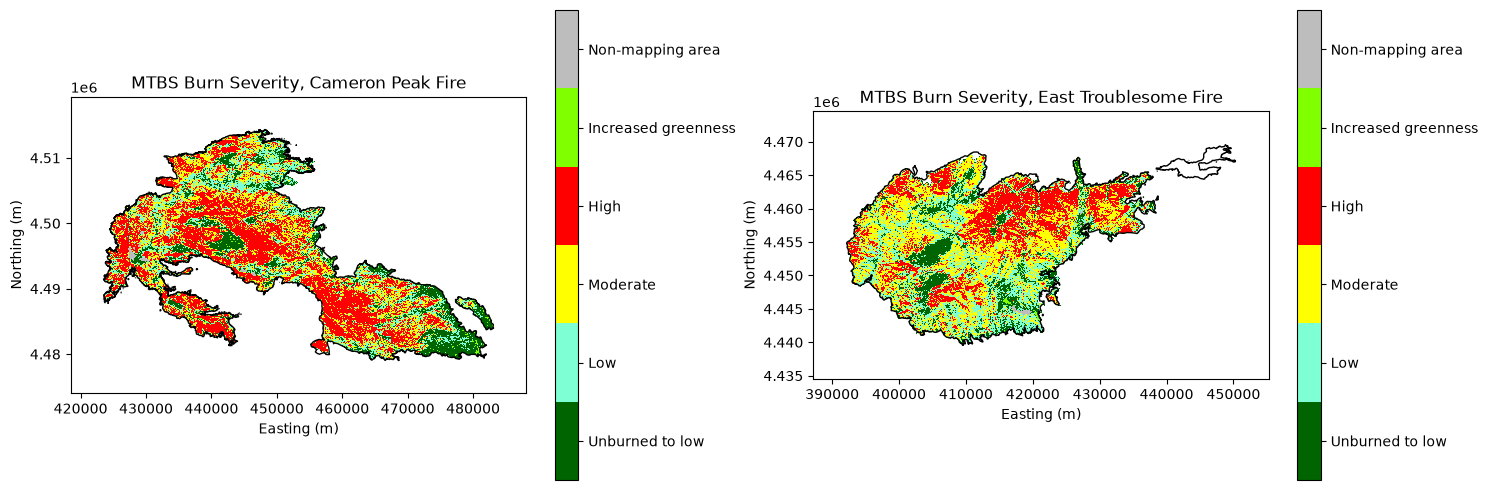

In [18]:
### MTBS class names and their standard colors
mtbs_names = ["Unburned to low", "Low", "Moderate", "High", "Increased greenness", "Non-mapping area"]
mtbs_cmap = ListedColormap(["#006400", "#7fffd4", "#ffff00", "#ff0000", "#7fff00", "#bdbdbd"])

### plot both maps side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, fire in zip(axes, study_areas):

    ### open the map, 0 is no data
    mtbs_da = rxr.open_rasterio(mtbs_paths[fire], masked=True).squeeze()

    ### plot the classes
    mtbs_plot = mtbs_da.plot(ax=ax, cmap=mtbs_cmap, vmin=0.5, vmax=6.5)
    mtbs_plot.colorbar.set_ticks(range(1, 7))
    mtbs_plot.colorbar.set_ticklabels(mtbs_names)

    ### add the fire perimeter
    perimeters_utm[perimeters_utm["fire"] == fire].boundary.plot(ax=ax, color="black", linewidth=1)

    ax.set_title("MTBS Burn Severity, " + fire.replace("_", " ").title() + " Fire")
    ax.set_xlabel("Easting (m)")
    ax.set_ylabel("Northing (m)")

plt.tight_layout()
plt.show()

Figure 3: The 2020 MTBS burn severity maps for each study area, with the NIFC perimeter in black.

# 4. Watersheds (USGS HUC12)
Next, the USGS Watershed Boundary Dataset is downloaded for the study areas. The dataset splits the US into nested watersheds, and the Hydrologic Unit Code 12 (HUC12) subwatersheds, the smallest level, are used. They will be used to summarize burn severity by watershed. The full detail polygons are slow to download and can time out, so they are simplified to about 20m.

In [19]:
### USGS Watershed Boundary Dataset, HUC12 layer
huc12_url = "https://hydro.nationalmap.gov/arcgis/rest/services/wbd/MapServer/6"
huc12_path = os.path.join(watershed_dir, "huc12.gpkg")

### load the subwatersheds if they're already saved, otherwise download them
if os.path.exists(huc12_path):
    huc12_gdf = gpd.read_file(huc12_path)
    print("Loaded saved subwatersheds from:", huc12_path)

else:
    huc12_list = []

    for fire, bounds in study_areas_latlon.items():
        fire_huc12_gdf = download_arcgis(
            huc12_url,
            bbox=bounds,
            out_fields="huc12,name,areasqkm,states",
            max_offset=0.0002
        )
        huc12_list.append(fire_huc12_gdf)

        print(fire + ":", len(fire_huc12_gdf), "subwatersheds")

    ### combine them, and drop subwatersheds that are in both study areas
    huc12_gdf = pd.concat(huc12_list, ignore_index=True).drop_duplicates("huc12")

### check it
huc12_gdf.head()


Loaded saved subwatersheds from: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\watersheds\huc12.gpkg


,huc12,name,areasqkm,states,geometry
0,101900060301,Upper Buckhorn Creek,110.85,CO,"POLYGON ((-105.41893 40.62125, -105.42194 40.6..."
1,101900060303,Redstone Creek,80.32,CO,"POLYGON ((-105.31804 40.62843, -105.31923 40.6..."
2,101900070802,Horsetooth Reservoir,44.52,CO,"POLYGON ((-105.17931 40.60031, -105.18263 40.6..."
3,101900070704,Milton Seaman Reservoir-North Fork Cache La Po...,123.59,CO,"POLYGON ((-105.31514 40.86858, -105.31843 40.8..."
4,101800100202,Running Water Creek-Sand Creek,171.28,"CO,WY","POLYGON ((-105.73259 41.10512, -105.73423 41.1..."


In [20]:
### plot the subwatersheds with the fire perimeters
huc12_plot = huc12_gdf.hvplot(
    geo=True,
    tiles="EsriImagery",
    title="HUC12 Subwatersheds Around the Fires",
    fill_color=None,
    line_color="white",
    line_width=1,
    hover_cols=["huc12", "name"],
    frame_width=600
)

huc12_plot * fires_plot

:Overlay
   .WMTS.I      :WMTS   [Longitude,Latitude]
   .Polygons.I  :Polygons   [Longitude,Latitude]   (huc12,name)
   .Polygons.II :Polygons   [Longitude,Latitude]

Figure 4: HUC12 subwatersheds (white) that overlap the study areas, with the fire perimeters in red.

In [21]:
### save the subwatersheds
huc12_path = os.path.join(watershed_dir, "huc12.gpkg")
huc12_gdf.to_file(huc12_path, driver="GPKG")

print("Saved subwatersheds to:", huc12_path)

Saved subwatersheds to: C:\Users\warno\Documents\GitHub\Fire_Burn_Severity\data\watersheds\huc12.gpkg


# 5. Wildland Urban Interface (WUI)
The WUI map comes from my [WUI Mapping Tool](https://github.com/maxwarnock/WUI_Mapping_Tool) output for Colorado (2019). This WUI map was clipped and saved in this repo here: "data/wui/wui_CO_2019_clip.tif". The clip covers both study areas plus 1km.

It is a 250m raster in the USA Contiguous Albers projection, where:

| Value | WUI class |
|---|---|
| 0 | Not WUI |
| 1 | Interface |
| 2 | Intermix |

The WUI map is left on its original 250m grid here. It will be matched to the 30m study area grid in the analysis notebooks.

In [22]:
### path to the WUI clip saved in the repo
wui_path = os.path.join(wui_dir, "wui_CO_2019_clip.tif")

### open the WUI clip
wui_da = rxr.open_rasterio(wui_path).squeeze()

### check the projection and pixel size
print(wui_da.rio.crs)
print(wui_da.rio.resolution())

ESRI:102039
(250.0, -250.0)


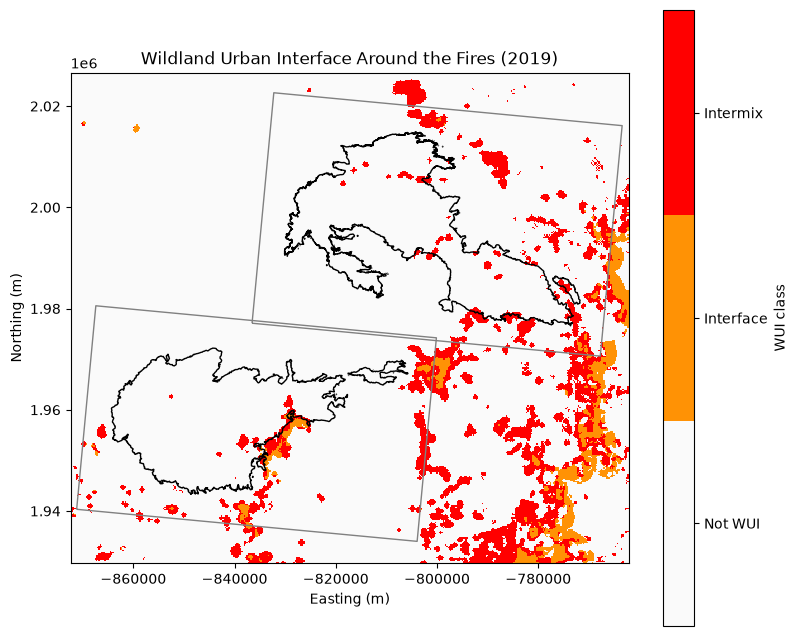

In [23]:
### WUI class names and colors
wui_names = ["Not WUI", "Interface", "Intermix"]
wui_cmap = ListedColormap(["#fafafa", "#ff9205", "#ff0000"])

### plot the WUI map
fig, ax = plt.subplots(figsize=(9, 8))

wui_plot = wui_da.plot(ax=ax, cmap=wui_cmap, vmin=-0.5, vmax=2.5)
wui_plot.colorbar.set_ticks([0, 1, 2])
wui_plot.colorbar.set_ticklabels(wui_names)
wui_plot.colorbar.set_label("WUI class")

### add the study areas and fire perimeters (in the WUI map's projection)
study_area_gdf.to_crs(wui_da.rio.crs).boundary.plot(ax=ax, color="gray", linewidth=1)
perimeters_gdf.to_crs(wui_da.rio.crs).boundary.plot(ax=ax, color="black", linewidth=1)

ax.set_title("Wildland Urban Interface Around the Fires (2019)")
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

plt.show()

Figure 5: WUI classes around the fire perimeters.

# 6. Harmonized Landsat and Sentinel-2 (HLS) Summer Composites
NASA's HLS data combines Landsat 8/9 and Sentinel-2 imagery into one 30m surface reflectance dataset. With both satellites together, there is a new image of the same place every 2-3 days.

Two indices are calculated from the HLS bands:
- Normalized Burn Ratio (NBR) = (NIR - SWIR2) / (NIR + SWIR2). Healthy vegetation has a high NBR, and burned areas have a low NBR. The drop in NBR from before to after a fire (dNBR) is used to map burn severity.
- Normalized Difference Vegetation Index (NDVI) = (NIR - Red) / (NIR + Red). This measures vegetation greenness, and will be used to track recovery after the fires.

| Band | Landsat (HLSL30) | Sentinel-2 (HLSS30) |
|---|---|---|
| Red | B04 | B04 |
| Near infrared (NIR) | B05 | B8A |
| Shortwave infrared 2 (SWIR2) | B07 | B12 |
| Quality mask | Fmask | Fmask |

Years: 2019 to 2026, one composite per fire for each year (8 per fire). 2019 is the summer before the fires, 2021 is the first summer after, and 2021-2026 are used to track recovery.

Summer window: June 1 to September 30 of each year. Burn severity is measured from the summer before the fires (2019) to the summer after (2021), with the same window both years, following the examples from [Parks et al. (2018)](https://doi.org/10.3390/rs10060879) and [Howe et al. (2022)](https://doi.org/10.3390/rs14205249). Vegetation greens up and dries out over each summer, so using the same dates every year keeps the seasonal changes controlled. The Cameron Peak Fire started on August 13, 2020, during the summer window, so its 2020 composite mixes before and after the fire. The East Troublesome Fire started on October 14, 2020, after the window, so its 2020 composite is still before the fire.

Median composite: Any single image can have clouds, smoke, or shadows. Taking the median of all of the clear looks at each pixel over the summer gives one clean image per year.

### Login to NASA Earthdata

In [24]:
### log in to NASA Earthdata (persist saves the login so you only enter it once)
earthaccess.login(persist=True)

In [25]:
### GDAL settings so rioxarray can read the HLS files directly from NASA's servers
### GDAL logs in with the Earthdata login that was saved above
netrc_name = "_netrc" if os.name == "nt" else ".netrc"
cookie_path = os.path.join(pathlib.Path.home(), "earthdata_cookies.txt")

os.environ["GDAL_HTTP_NETRC"] = "YES"
os.environ["GDAL_HTTP_NETRC_FILE"] = os.path.join(pathlib.Path.home(), netrc_name)
os.environ["GDAL_HTTP_COOKIEFILE"] = cookie_path
os.environ["GDAL_HTTP_COOKIEJAR"] = cookie_path

### only read the files we ask for, and retry if the connection drops
os.environ["GDAL_DISABLE_READDIR_ON_OPEN"] = "EMPTY_DIR"
os.environ["CPL_VSIL_CURL_ALLOWED_EXTENSIONS"] = "TIF"
os.environ["GDAL_HTTP_MAX_RETRY"] = "5"
os.environ["GDAL_HTTP_RETRY_DELAY"] = "2"

### HLS settings

In [26]:
### HLS products: Landsat 8/9 (L30) and Sentinel-2 (S30)
hls_products = ["HLSL30", "HLSS30"]

### HLS band names for red, near infrared, shortwave infrared 2, and the quality mask
hls_bands = {
    "HLSL30": {"red": "B04", "nir": "B05", "swir2": "B07", "fmask": "Fmask"},
    "HLSS30": {"red": "B04", "nir": "B8A", "swir2": "B12", "fmask": "Fmask"},
}

### years to build composites for
hls_years = list(range(2019, 2027))

### summer window used every year (month-day)
summer_start = "06-01"
summer_end = "09-30"

### skip scenes that are mostly cloudy (percent)
max_cloud_cover = 80

### Define the HLS search function
This function searches NASA Earthdata for all of the HLS scenes over a study area during the summer window, and makes a table with one row per scene and the links to the four files needed. A scene is one satellite image of one tile on one day.

In [27]:
### create a function to search for HLS scenes
def search_hls(bounds_latlon, year):
    """
    Search NASA Earthdata for HLS scenes over a study area in the summer window

    Args:
    bounds_latlon (tuple): study area box in lat/lon (min lon, min lat, max lon, max lat)
    year (int): year to search

    Returns:
    pandas.DataFrame: one row per scene, with links to the red, nir, swir2, and fmask files
    """

    ### start an empty list for the scene rows
    rows = []

    ### search Landsat and Sentinel-2 separately
    for product in hls_products:
        results = earthaccess.search_data(
            short_name=product,
            version="2.0",
            bounding_box=bounds_latlon,
            temporal=(str(year) + "-" + summer_start, str(year) + "-" + summer_end),
            cloud_cover=(0, max_cloud_cover)
        )

        for granule in results:

            ### scene name, e.g. HLS.L30.T13TDE.2021180T174137.v2.0
            scene_name = granule["umm"]["GranuleUR"]
            name_parts = scene_name.split(".")

            ### scene info (the date is the year and day of the year, e.g. 2021180)
            row = {
                "scene": scene_name,
                "product": product,
                "tile": name_parts[2],
                "date": pd.to_datetime(name_parts[3][:7], format="%Y%j"),
            }

            ### find the link for each file we need
            for band_name, band_code in hls_bands[product].items():
                for link in granule.data_links():
                    if link.endswith("." + band_code + ".tif"):
                        row[band_name] = link

            ### only keep scenes that have all four files
            if all(band_name in row for band_name in hls_bands[product]):
                rows.append(row)

    return pd.DataFrame(rows)

In [28]:
### test the search function on one fire and year
test_scenes_df = search_hls(study_areas_latlon["cameron_peak"], 2021)

print("Found", len(test_scenes_df), "scenes")
test_scenes_df.head()

Found 76 scenes


,scene,product,tile,date,red,nir,swir2,fmask
0,HLS.L30.T13TDF.2021154T174250.v2.0,HLSL30,T13TDF,2021-06-03,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...
1,HLS.L30.T13TDE.2021154T174314.v2.0,HLSL30,T13TDE,2021-06-03,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...
2,HLS.L30.T13TDF.2021163T173643.v2.0,HLSL30,T13TDF,2021-06-12,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...
3,HLS.L30.T13TDE.2021163T173707.v2.0,HLSL30,T13TDE,2021-06-12,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...
4,HLS.L30.T13TDE.2021170T174320.v2.0,HLSL30,T13TDE,2021-06-19,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...,https://data.lpdaac.earthdatacloud.nasa.gov/lp...


### Define the cloud mask function
Each HLS image has a quality band called Fmask, where each pixel's value stores yes/no flags as bits. Pixels flagged as cloud, next to a cloud, cloud shadow, snow/ice, water, or high aerosol (smoke and haze) are removed.

| Bit | Meaning |
|---|---|
| 1 | Cloud |
| 2 | Adjacent to cloud or shadow |
| 3 | Cloud shadow |
| 4 | Snow/ice |
| 5 | Water |
| 6-7 | Aerosol level (both bits set = high) |

Each bit is a yes/no flag. Pixels are removed in two steps:
1. Values of 192 or more are removed. Bits 6 and 7 are both yes for these values, which means high aerosol. The no data value (255) is also above 192, so it gets removed too. Low and moderate aerosol (only one of bits 6 and 7 is yes) are kept.
2. Bits 1-5 are checked one at a time. To check bit n, divide the Fmask value by 2<sup>n</sup>, round down, and see if the result is odd (odd means yes). If any of bits 1-5 is yes, the pixel is removed. For example, for a value of 72, 72 ÷ 8 = 9, which is odd, so bit 3 (cloud shadow) is yes and the pixel is removed.


The bits and the decoding method follow Table 9 and Appendix A of the HLS User Guide (Ju et al., 2026).


In [29]:
### create a function to find the clear pixels in an Fmask layer
def clear_mask(fmask_da):
    """
    Find the clear pixels in an HLS Fmask layer

    Args:
    fmask_da (xarray.DataArray): HLS Fmask layer

    Returns:
    xarray.DataArray: True where the pixel is clear
    """

    ### remove high aerosol and no data (values of 192 or more)
    clear = fmask_da < 192

    ### remove cloud (bit 1), adjacent to cloud (2), cloud shadow (3), snow/ice (4), and water (5)
    for bit in [1, 2, 3, 4, 5]:
        bit_is_set = (fmask_da // 2**bit) % 2 == 1
        clear = clear & ~bit_is_set

    return clear

### Define the functions to calculate NBR and NDVI
These functions below open the four files for one image, crop them to the study area, remove the cloudy pixels, and calculate NBR and NDVI. HLS reflectance is stored as whole numbers (reflectance x 10,000), but the scale factor cancels out in the index formulas, so it isn't needed. Pixels with zero or negative reflectance are also removed, since they are not real values.

Each result is then put on the study area grid, so that images from different tiles line up with each other.

In [30]:
### create a function to open one HLS file and crop it to the study area
def open_hls_band(url, bounds, masked=True):
    """
    Open one HLS band file from NASA's servers and crop it to the study area

    Args:
    url (str): link to the HLS file
    bounds (tuple): study area box in UTM zone 13N (minx, miny, maxx, maxy)
    masked (bool): turn the no data values into NaN

    Returns:
    xarray.DataArray: the cropped band
    """

    ### open the file and remove the extra band dimension
    band_da = rxr.open_rasterio(url, masked=masked).squeeze()

    ### crop it and read the pixels into memory
    return band_da.rio.clip_box(*bounds).load()

In [31]:
### create a function to make an empty 30m grid for a study area
def make_study_area_grid(bounds):
    """
    Make an empty 30m grid that covers a study area box

    Args:
    bounds (tuple): study area box in UTM zone 13N (minx, miny, maxx, maxy)

    Returns:
    xarray.DataArray: grid of NaN values with x and y pixel center coordinates
    """

    ### unpack the box
    minx, miny, maxx, maxy = bounds

    ### pixel center coordinates (y goes from top to bottom)
    x = np.arange(minx + cell_size / 2, maxx, cell_size)
    y = np.arange(maxy - cell_size / 2, miny, -cell_size)

    ### make the grid
    grid_da = xr.DataArray(
        np.full((len(y), len(x)), np.nan, dtype="float32"),
        coords={"y": y, "x": x},
        dims=("y", "x")
    )

    return grid_da.rio.write_crs(utm_crs)

In [32]:
### create a function to calculate NBR and NDVI for one scene
def scene_indices(scene, bounds, grid_da):
    """
    Open one HLS scene, mask clouds, and calculate NBR and NDVI on the study area grid

    Args:
    scene (pandas.Series): one row from the search_hls table
    bounds (tuple): study area box in UTM zone 13N
    grid_da (xarray.DataArray): empty study area grid from make_study_area_grid

    Returns:
    xarray.DataArray: NBR, NaN where the pixel isn't clear
    xarray.DataArray: NDVI, NaN where the pixel isn't clear
    """

    ### open the four files (keep Fmask as whole numbers to check the bits)
    fmask = open_hls_band(scene["fmask"], bounds, masked=False)
    red = open_hls_band(scene["red"], bounds)
    nir = open_hls_band(scene["nir"], bounds)
    swir2 = open_hls_band(scene["swir2"], bounds)

    ### keep clear pixels with positive reflectance in all three bands
    valid = clear_mask(fmask) & (red > 0) & (nir > 0) & (swir2 > 0)

    ### calculate the indices
    nbr = ((nir - swir2) / (nir + swir2)).where(valid)
    ndvi = ((nir - red) / (nir + red)).where(valid)

    ### put them on the study area grid (pixels outside this tile are NaN)
    nbr = nbr.reindex_like(grid_da, method="nearest", tolerance=1)
    ndvi = ndvi.reindex_like(grid_da, method="nearest", tolerance=1)

    return nbr, ndvi

### Define the composite function
This is the wrapper function that builds the composites for one fire and one year:
1. Search for all of the summer images
2. Calculate NBR and NDVI for each image. Images from the same satellite on the same day (but different tiles) are joined into one layer, so the overlap between tiles isn't counted twice
3. Stack the layers and take the median of each pixel
4. Count how many clear measurements each pixel had
5. Save the NBR, NDVI, and clear count rasters, and a table of the images used

In [33]:
### create a wrapper function to build the summer composites for one fire and year
def build_hls_composites(fire, year, out_paths):
    """
    Build and save the summer median NBR and NDVI composites for one fire and year

    Args:
    fire (str): short fire name (cameron_peak or east_troublesome)
    year (int): year of the composite
    out_paths (dict): paths to save the nbr, ndvi, count, and scenes files

    Returns:
    None
    """

    ### study area box and empty grid
    bounds = study_areas[fire]
    grid_da = make_study_area_grid(bounds)

    ### fire and year for the progress messages, e.g. cameron_peak 2021
    label = fire + " " + str(year)

    ### search for the scenes
    scenes_df = search_hls(study_areas_latlon[fire], year)
    scenes_df["status"] = "ok"
    print(label + ": found", len(scenes_df), "scenes")

    ### calculate NBR and NDVI for each scene, with one layer per satellite and day
    nbr_layers = {}
    ndvi_layers = {}

    for i, scene in tqdm(scenes_df.iterrows(), total=len(scenes_df), desc=label):

        ### skip scenes that don't open (e.g. connection errors, or tiles outside the box)
        try:
            nbr, ndvi = scene_indices(scene, bounds, grid_da)
        except Exception as error:
            print("  Skipped " + scene["scene"] + ":", error)
            scenes_df.loc[i, "status"] = "skipped"
            continue

        ### satellite and day, e.g. HLSL30_2021-06-29
        layer_name = scene["product"] + "_" + scene["date"].strftime("%Y-%m-%d")

        ### join tiles from the same satellite and day
        if layer_name in nbr_layers:
            nbr_layers[layer_name] = nbr_layers[layer_name].combine_first(nbr)
            ndvi_layers[layer_name] = ndvi_layers[layer_name].combine_first(ndvi)
        else:
            nbr_layers[layer_name] = nbr
            ndvi_layers[layer_name] = ndvi

    ### stop if no scenes could be read
    if not nbr_layers:
        print(label + ": no scenes could be read, skipping")
        return

    ### stack the layers
    nbr_stack = xr.concat(list(nbr_layers.values()), dim="layer")
    ndvi_stack = xr.concat(list(ndvi_layers.values()), dim="layer")

    ### take the median of the clear looks at each pixel
    nbr_median = nbr_stack.median(dim="layer")
    ndvi_median = ndvi_stack.median(dim="layer")

    ### count the clear looks at each pixel
    clear_count = nbr_stack.notnull().sum(dim="layer").astype("uint8")

    ### save the rasters
    nbr_median.rio.write_crs(utm_crs).rio.write_nodata(np.nan).rio.to_raster(out_paths["nbr"], compress="deflate")
    ndvi_median.rio.write_crs(utm_crs).rio.write_nodata(np.nan).rio.to_raster(out_paths["ndvi"], compress="deflate")
    clear_count.rio.write_crs(utm_crs).rio.to_raster(out_paths["count"], compress="deflate")

    ### save the scene table
    scenes_df.to_csv(out_paths["scenes"], index=False)

    print(label + ": saved composites from", len(nbr_layers), "layers (median of", int(clear_count.median()), "clear looks per pixel)")

### Run the composite function for both fires and all years
This step can take a few hours.

In [34]:
### run the wrapper function for each fire and year
hls_paths = {}

for fire in study_areas:

    ### make a folder for this fire's composites
    fire_hls_dir = os.path.join(hls_dir, fire)
    os.makedirs(fire_hls_dir, exist_ok=True)

    for year in hls_years:

        ### file paths for this fire and year
        file_start = "hls_" + fire + "_" + str(year)
        out_paths = {
            "nbr": os.path.join(fire_hls_dir, file_start + "_nbr.tif"),
            "ndvi": os.path.join(fire_hls_dir, file_start + "_ndvi.tif"),
            "count": os.path.join(fire_hls_dir, file_start + "_count.tif"),
            "scenes": os.path.join(fire_hls_dir, file_start + "_scenes.csv"),
        }
        hls_paths[(fire, year)] = out_paths

        ### skip composites that are already done
        if all(os.path.exists(path) for path in out_paths.values()):
            print(fire + " " + str(year) + ": already done")
            continue

        build_hls_composites(fire, year, out_paths)

cameron_peak 2019: already done
cameron_peak 2020: already done
cameron_peak 2021: already done
cameron_peak 2022: already done
cameron_peak 2023: already done
cameron_peak 2024: already done
cameron_peak 2025: already done
cameron_peak 2026: already done
east_troublesome 2019: already done
east_troublesome 2020: already done
east_troublesome 2021: already done
east_troublesome 2022: already done
east_troublesome 2023: already done
east_troublesome 2024: already done
east_troublesome 2025: already done
east_troublesome 2026: already done


### Check the composites: NBR before and after the fires

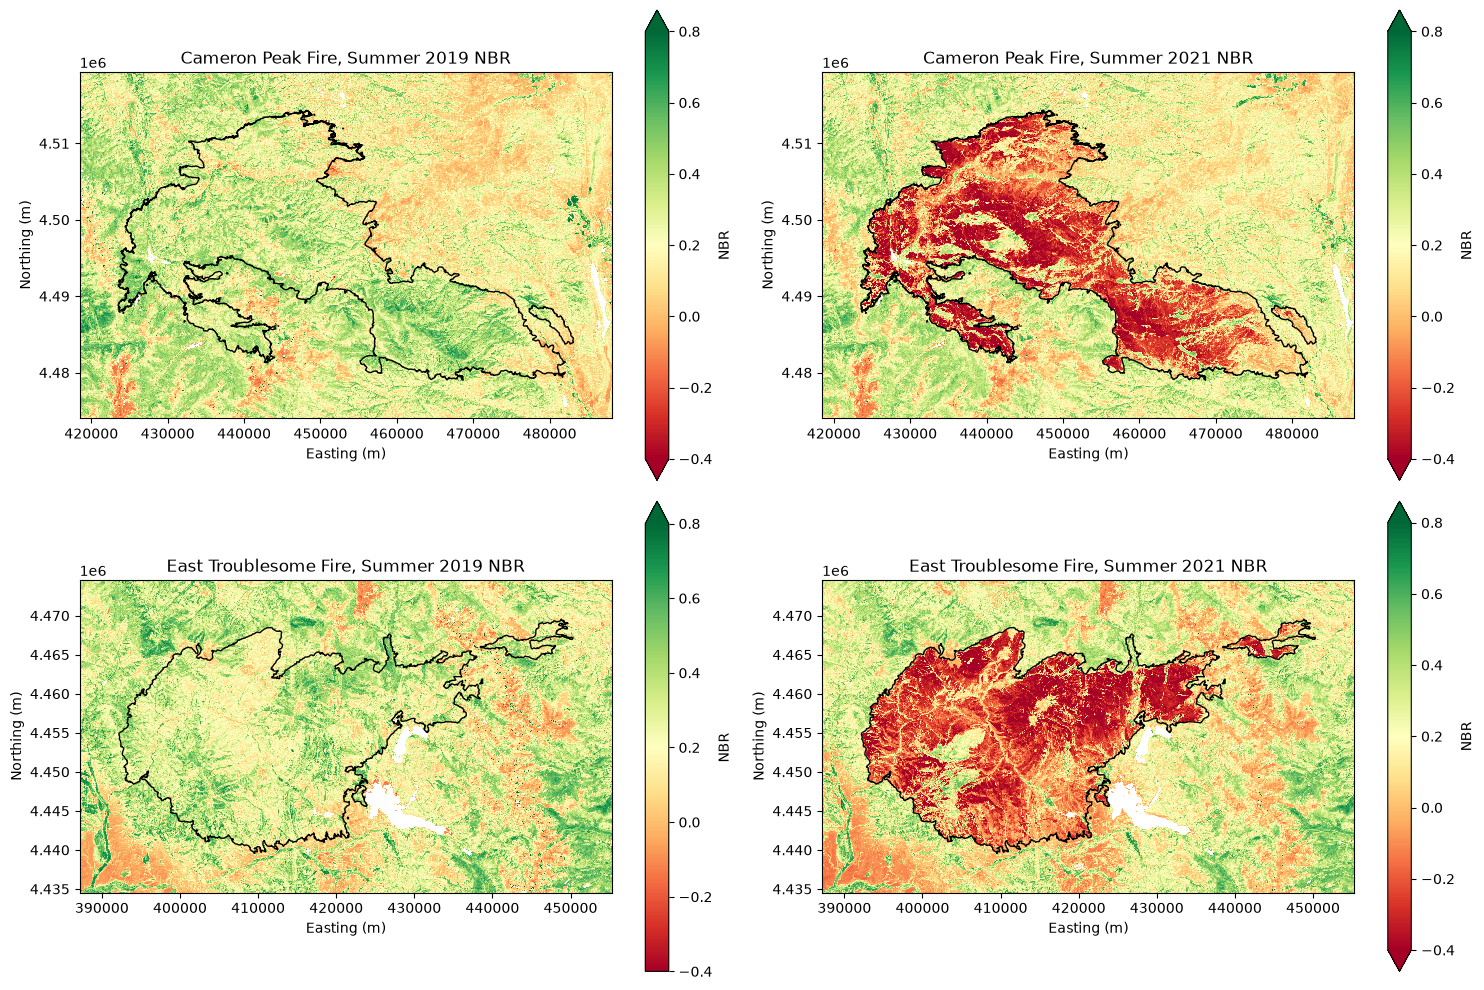

In [35]:
### plot the 2019 (before) and 2021 (after) NBR composites for both fires
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for row, fire in enumerate(study_areas):
    for col, year in enumerate([2019, 2021]):
        ax = axes[row, col]

        ### open the NBR composite
        nbr_da = rxr.open_rasterio(hls_paths[(fire, year)]["nbr"], masked=True).squeeze()

        ### plot it
        nbr_plot = nbr_da.plot(ax=ax, cmap="RdYlGn", vmin=-0.4, vmax=0.8)
        nbr_plot.colorbar.set_label("NBR")

        ### add the fire perimeter
        perimeters_utm[perimeters_utm["fire"] == fire].boundary.plot(ax=ax, color="black", linewidth=1)

        ax.set_title(fire.replace("_", " ").title() + " Fire, Summer " + str(year) + " NBR")
        ax.set_xlabel("Easting (m)")
        ax.set_ylabel("Northing (m)")

plt.tight_layout()
plt.show()

Figure 6: Summer median NBR before (2019) and after (2021) each fire. Burned areas inside the perimeters drop from high NBR (green) to low NBR (orange and red).

# Universal Calls for the Downloaded Data
Copy this cell into the analysis notebooks to load the data saved here.

In [36]:
### root dir
data_dir = os.path.join(repo_root, 'data')

### fire names used in the file names
fire_keys = ["cameron_peak", "east_troublesome"]


### PERIMETERS AND STUDY AREAS
perimeters_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'nifc_perimeters.gpkg'))
study_area_gdf = gpd.read_file(os.path.join(data_dir, 'perimeters', 'study_areas.gpkg'))


### MTBS
### fire records and dNBR thresholds
mtbs_fires_df = pd.read_csv(os.path.join(data_dir, 'mtbs', 'mtbs_fires.csv'))

### MTBS boundaries
mtbs_gdf = gpd.read_file(os.path.join(data_dir, 'mtbs', 'mtbs_boundaries.gpkg'))

### MTBS burn severity maps
mtbs_paths = {}
for fire in fire_keys:
    mtbs_paths[fire] = os.path.join(data_dir, 'mtbs', 'mtbs_' + fire + '_2020.tif')


### WATERSHEDS
huc12_gdf = gpd.read_file(os.path.join(data_dir, 'watersheds', 'huc12.gpkg'))


### WUI
wui_path = os.path.join(data_dir, 'wui', 'wui_CO_2019_clip.tif')


### HLS COMPOSITES
### e.g. hls_paths[("cameron_peak", 2021)]["nbr"]
hls_paths = {}
for fire in fire_keys:
    for year in range(2019, 2027):
        fire_hls_dir = os.path.join(data_dir, 'hls', fire)
        file_start = "hls_" + fire + "_" + str(year)
        hls_paths[(fire, year)] = {
            "nbr": os.path.join(fire_hls_dir, file_start + "_nbr.tif"),
            "ndvi": os.path.join(fire_hls_dir, file_start + "_ndvi.tif"),
            "count": os.path.join(fire_hls_dir, file_start + "_count.tif"),
            "scenes": os.path.join(fire_hls_dir, file_start + "_scenes.csv"),
        }

# Citations
The HLS summer window in section 6 (June 1 to September 30, comparing the summer before the fires to the summer after) follows Howe et al. (2022) and Parks et al. (2018), and the HLS cloud mask follows the HLS User Guide (Ju et al., 2026).

- Howe, A. A., Parks, S. A., Harvey, B. J., Saberi, S. J., Lutz, J. A., & Yocom, L. L. (2022). Comparing Sentinel-2 and Landsat 8 for burn severity mapping in western North America. *Remote Sensing, 14*(20), 5249. https://doi.org/10.3390/rs14205249
- Ju, J., Neigh, C., Sridhar, M., Claverie, M., Skakun, S., Roger, J.-C., Vermote, E., Dungan, J., & Ashokkumar, L. (2026). *Harmonized Landsat and Sentinel-2 (HLS) Product User Guide, Product Version 2.0*. NASA Land Processes Distributed Active Archive Center. https://lpdaac.usgs.gov/documents/1698/HLS_User_Guide_V2.pdf
- Parks, S. A., Holsinger, L. M., Voss, M. A., Loehman, R. A., & Robinson, N. P. (2018). Mean composite fire severity metrics computed with Google Earth Engine offer improved accuracy and expanded mapping potential. *Remote Sensing, 10*(6), 879. https://doi.org/10.3390/rs10060879
